In [2]:

import pandas as pd
import numpy as np

data = {
    "product_name": [
        "Headphones", "Phone Case", "Laptop", "Mouse",
        "Keyboard", "Headphones", "Phone Case", "Laptop",
        "Mouse", "Keyboard", "Headphones", "Laptop",
        "Mouse", "Phone Case", "Keyboard", "Headphones",
        "Laptop", "Mouse", "Phone Case", "Keyboard"
    ],
    "review": [
        "Excellent sound and great quality",
        "Very strong and useful case",
        "Fast and powerful laptop",
        "Works smoothly and perfectly",
        "Comfortable keys and good design",
        "Amazing sound and battery life",
        "Poor quality and breaks easily",
        "Very slow and disappointing",
        "Stopped working quickly",
        "Keys are difficult to press",
        "Good sound for the price",
        "Excellent performance",
        "Easy to use and reliable",
        "Average product quality",
        "Great keyboard for typing",
        "Bad sound and uncomfortable",
        "Battery life is very poor",
        "Good value for money",
        "Cheap material and bad fit",
        "Very comfortable and responsive"
    ],
    "rating": [
        5, 5, 5, 4, 4, 5, 1, 2, 1, 2,
        4, 5, 4, 3, 5, 1, 2, 4, 1, 5
    ]
}

df = pd.DataFrame(data)

# Handle missing values
df = df.dropna(subset=["rating", "review"])
df["product_name"] = df["product_name"].fillna("")
df["review"] = df["review"].astype(str).str.lower().str.strip()

# Combine product information and review text
df["text"] = df["product_name"] + " " + df["review"]

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (20, 4)


,product_name,review,rating,text
0,Headphones,excellent sound and great quality,5,Headphones excellent sound and great quality
1,Phone Case,very strong and useful case,5,Phone Case very strong and useful case
2,Laptop,fast and powerful laptop,5,Laptop fast and powerful laptop
3,Mouse,works smoothly and perfectly,4,Mouse works smoothly and perfectly
4,Keyboard,comfortable keys and good design,4,Keyboard comfortable keys and good design


In [3]:

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

vocab_size = 500
max_length = 12

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(df["text"])

sequences = tokenizer.texts_to_sequences(df["text"])

X = pad_sequences(
    sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

y = df["rating"].values.astype("float32")

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Encoded review:", X_train[0])


Training records: 15
Testing records: 5
Encoded review: [ 6 31  7  2 18 19  0  0  0  0  0  0]


model train

In [4]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

tf.random.set_seed(42)

model = Sequential([
    Embedding(input_dim=vocab_size, output_dim=16),
    LSTM(16),
    Dropout(0.2),
    Dense(8, activation="relu"),
    Dense(1, activation="linear")
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=4,
    validation_split=0.2,
    verbose=1
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 189ms/step - loss: 14.1805 - mae: 3.5019 - val_loss: 13.9142 - val_mae: 3.3210
Epoch 2/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 14.0678 - mae: 3.4845 - val_loss: 13.7957 - val_mae: 3.3035
Epoch 3/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 13.8960 - mae: 3.4615 - val_loss: 13.6293 - val_mae: 3.2785
Epoch 4/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - loss: 13.7083 - mae: 3.4349 - val_loss: 13.4116 - val_mae: 3.2456
Epoch 5/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 13.4133 - mae: 3.3899 - val_loss: 13.1529 - val_mae: 3.2061
Epoch 6/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 13.1704 - mae: 3.3551 - val_loss: 12.8530 - val_mae: 3.1598
Epoch 7/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 12.9064 - mae: 3.3140 - val_loss: 12.5116 - val_mae: 3.1064
Epoch 8/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - loss: 12.4551 - mae: 3.2460 - val_loss: 12.1049 - val_mae: 3.0417
Epoch 9/30
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - loss: 12.048

In [5]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

predictions = model.predict(X_test, verbose=0).flatten()

# Ratings range from 1 to 5 in this example
predictions = np.clip(predictions, 1, 5)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("Model Evaluation")
print("----------------")
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))


Model Evaluation
----------------
MAE: 1.699
RMSE: 1.961
R2 Score: -0.145


,Actual Rating,Predicted Rating,Absolute Error
0,5.0,3.75,1.25
1,4.0,3.76,0.24
2,1.0,3.78,2.78
3,5.0,3.58,1.42
4,1.0,3.80,2.80


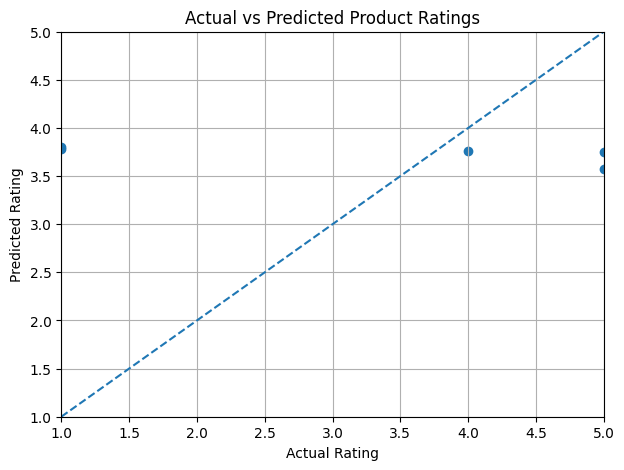

In [6]:

import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Actual Rating": y_test,
    "Predicted Rating": np.round(predictions, 2)
})

comparison["Absolute Error"] = np.round(
    np.abs(comparison["Actual Rating"] -
           comparison["Predicted Rating"]), 2
)

display(comparison)

plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions)
plt.plot([1, 5], [1, 5], linestyle="--")
plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted Product Ratings")
plt.xlim(1, 5)
plt.ylim(1, 5)
plt.grid(True)
plt.show()


In [7]:

new_reviews = pd.DataFrame({
    "product_name": ["Headphones", "Laptop", "Mouse"],
    "review": [
        "Excellent product with amazing quality",
        "Very poor performance and bad battery",
        "Good product and easy to use"
    ]
})

new_reviews["text"] = (
    new_reviews["product_name"] + " " +
    new_reviews["review"].str.lower()
)

new_sequences = tokenizer.texts_to_sequences(
    new_reviews["text"]
)

new_X = pad_sequences(
    new_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

new_predictions = model.predict(new_X, verbose=0).flatten()
new_predictions = np.clip(new_predictions, 1, 5)

for review, rating in zip(
    new_reviews["review"], new_predictions
):
    print("Review:", review)
    print("Predicted rating:", round(float(rating), 2), "/ 5")
    print()


Review: Excellent product with amazing quality
Predicted rating: 3.73 / 5

Review: Very poor performance and bad battery
Predicted rating: 3.69 / 5

Review: Good product and easy to use
Predicted rating: 3.7 / 5



In [8]:

model.save("amazon_rating_lstm.keras")
print("Model saved successfully!")


Model saved successfully!


In [9]:

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (4, 12, 16)            │         8,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (4, 16)                │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (4, 16)                │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (4, 8)                 │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (4, 1)                 │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,773 (120.21 KB)

 Trainable params: 10,257 (40.07 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 20,516 (80.14 KB)

In [11]:

import pandas as pd

predictions = model.predict(X_test).flatten()

results = pd.DataFrame({
    "Actual Rating": y_test,
    "Predicted Rating": predictions.round(2)
})

print(results)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
   Actual Rating  Predicted Rating
0            5.0              3.75
1            4.0              3.76
2            1.0              3.78
3            5.0              3.58
4            1.0              3.80
